# dθ/dQ versus interpolation mesh (Y₂Ir₂O₇, production)

∂θ/∂Q at Q = 0.01 Å of the three Γ₂⁻ patterns on uniform N³ grids, production window `f12.422_w22.644_k8`
(base 220455, PAW-overlap trial functions, pinned τ). N = 10 is the production pair (`dtheta_GM2-_p<m>_Q0.01`,
pipeline step 7); N = 4, 6, 8, 12 are `dtheta_nk<N>_GM2-_p<m>_Q0.01` (2026-11-03,
`analysis/validation/2026-11-03_k_sweeps/c2_variant.sh`, jobs 220779–220802). On a uniform grid ∂θ/∂Q is the mean of
c₂. Filled: undistorted-structure estimate; open: displaced-structure estimate (their spread is O(Q²), a linearity
test, not a validity test). The paper figure is Fig. 6(a) (`../figures/fig6.ipynb`).


In [1]:
# ---- settings
from pathlib import Path
WINDOW = Path("/Users/treycole/Repos/axion-phonon/data/Y2Ir2O7/windows/f12.422_w22.644_k8")
PATTERNS = {1: "Y", 2: "Ir", 3: "O(48f)"}
NKS = (4, 6, 8, 10, 12)
FOLDER = lambda m, n: WINDOW / (f"dtheta_GM2-_p{m}_Q0.01" if n == 10 else f"dtheta_nk{n}_GM2-_p{m}_Q0.01")
# ---------------


pattern                      N = 4                   N = 6                   N = 8                  N = 10                  N = 12
1 (Y):      -0.017119   -0.017214   -0.017118   -0.017214   -0.017114   -0.017210   -0.017114   -0.017210   -0.017114   -0.017210 
2 (Ir):     +0.051503   +0.051120   +0.054978   +0.054555   +0.055021   +0.054596   +0.055021   +0.054596   +0.055021   +0.054597 
3 (O(48f)):  +0.062362   +0.062327   +0.063860   +0.063824   +0.063867   +0.063830   +0.063867   +0.063830   +0.063867   +0.063830 


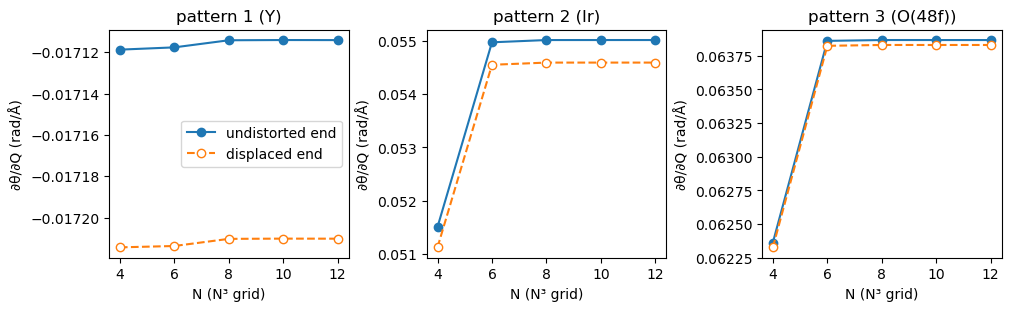

In [2]:
import numpy as np
import matplotlib.pyplot as plt


def dtheta(folder):
    """(undistorted end, displaced end) of a uniform-grid pair: mean of c2 over c2.npz, or over the step-6 chunks."""
    if (folder / "c2.npz").exists():
        return np.load(folder / "c2.npz")["c2"].real.mean(0)
    parts = [np.load(f)["c2"] for f in sorted(folder.glob("c2/out*/chunks/chunk_*.npz"))]
    c2 = np.concatenate(parts)
    assert len(c2) == len(np.load(folder / "klist.npz")["k"]), f"{folder}: missing chunks"
    return c2.real.mean(0)


table = {m: np.array([dtheta(FOLDER(m, n)) for n in NKS]) for m in PATTERNS}
print(f"{'pattern':10s}" + "".join(f"{f'N = {n}':>24s}" for n in NKS))
for m, name in PATTERNS.items():
    print(f"{m} ({name}):".ljust(10) + "".join(f"{v[0]:+11.6f} {v[1]:+11.6f} " for v in table[m]))
fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout="constrained")
for ax, (m, name) in zip(axes, PATTERNS.items()):
    ax.plot(NKS, table[m][:, 0], "o-", label="undistorted end")
    ax.plot(NKS, table[m][:, 1], "o--", mfc="white", label="displaced end")
    ax.set(title=f"pattern {m} ({name})", xlabel="N (N³ grid)", ylabel="∂θ/∂Q (rad/Å)")
axes[0].legend()
plt.show()
